
# Credit Scoring Model

## 1. Project Introduction

This project is part of the CodeAlpha Machine Learning Internship.

The objective is to predict an individual's creditworthiness using historical financial and personal information.

This is a binary classification problem:

- 0 = Bad creditworthiness
- 1 = Good creditworthiness

The project compares Logistic Regression, Decision Tree, and Random Forest classifiers using appropriate classification evaluation metrics.


In [1]:

# ==========================================
# DATASET LOADING AND INITIAL CHECK
# ==========================================
import pandas as pd
import numpy as np

# Update this path if your CSV has a different filename.
file_path = "../data/credit_dataset.csv"

# Load dataset
df = pd.read_csv(file_path)

# Display first five rows
print("FIRST FIVE ROWS:")
display(df.head())

# Dataset dimensions
print("\nDATASET SHAPE:")
print(df.shape)

# Column names
print("\nCOLUMN NAMES:")
print(df.columns.tolist())

# Data types and non-null counts
print("\nDATASET INFORMATION:")
df.info()

# Missing values
print("\nMISSING VALUES:")
print(df.isnull().sum())

# Missing value percentages
print("\nMISSING VALUE PERCENTAGES:")
print((df.isnull().mean() * 100).round(2))

# Duplicate rows
print("\nDUPLICATE ROWS:")
print(df.duplicated().sum())

# Basic numerical statistics
print("\nNUMERICAL SUMMARY:")
display(df.describe())

# Categorical summary
print("\nCATEGORICAL SUMMARY:")
display(df.describe(include="object"))


FIRST FIVE ROWS:


,Age,Gender,Education,Income,Debt,Credit_Score,Loan_Amount,Loan_Term,Num_Credit_Cards,Payment_History,Employment_Status,Residence_Type,Marital_Status,Creditworthiness
0,56,Female,Master,149406,34089,581,49200,60,4,Bad,Unemployed,Rented,Single,1
1,69,Female,High School,78896,8626,648,20147,24,7,Good,Employed,Mortgaged,Married,1
2,46,Female,Master,119339,46281,329,41307,12,8,Bad,Unemployed,Owned,Single,1
3,32,Male,High School,131067,29403,816,19019,60,8,Bad,Employed,Owned,Single,1
4,60,Male,PhD,38001,30032,673,16317,36,4,Average,Employed,Rented,Married,0



DATASET SHAPE:
(12000, 14)

COLUMN NAMES:
['Age', 'Gender', 'Education', 'Income', 'Debt', 'Credit_Score', 'Loan_Amount', 'Loan_Term', 'Num_Credit_Cards', 'Payment_History', 'Employment_Status', 'Residence_Type', 'Marital_Status', 'Creditworthiness']

DATASET INFORMATION:
<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Age                12000 non-null  int64
 1   Gender             12000 non-null  str  
 2   Education          12000 non-null  str  
 3   Income             12000 non-null  int64
 4   Debt               12000 non-null  int64
 5   Credit_Score       12000 non-null  int64
 6   Loan_Amount        12000 non-null  int64
 7   Loan_Term          12000 non-null  int64
 8   Num_Credit_Cards   12000 non-null  int64
 9   Payment_History    12000 non-null  str  
 10  Employment_Status  12000 non-null  str  
 11  Residence_Type     12000 

,Age,Income,Debt,Credit_Score,Loan_Amount,Loan_Term,Num_Credit_Cards,Creditworthiness
count,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000
mean,43.489250,85222.009417,25354.673250,573.967583,25113.951250,35.943000,4.985833,0.702583
std,14.908982,37640.043409,14087.390846,157.816052,14247.092051,16.965162,2.593458,0.457140
min,18.000000,20026.000000,1001.000000,300.000000,501.000000,12.000000,1.000000,0.000000
25%,31.000000,52400.750000,13161.000000,437.000000,12725.000000,24.000000,3.000000,0.000000
50%,43.000000,85756.000000,25382.500000,574.000000,25220.500000,36.000000,5.000000,1.000000
75%,56.000000,117754.750000,37497.500000,709.000000,37348.000000,48.000000,7.000000,1.000000
max,69.000000,149984.000000,49995.000000,849.000000,49996.000000,60.000000,9.000000,1.000000



CATEGORICAL SUMMARY:


C:\Users\Ubaid CH\AppData\Local\Temp\ipykernel_16244\2658576040.py:47: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include="object"))


,Gender,Education,Payment_History,Employment_Status,Residence_Type,Marital_Status
count,12000,12000,12000,12000,12000,12000
unique,2,4,3,3,3,3
top,Female,PhD,Good,Self-Employed,Owned,Married
freq,6012,3033,4045,4046,4051,4012


In [2]:

# ==========================================
# TARGET VARIABLE INSPECTION
# ==========================================

# Replace None with the EXACT target column name
# after inspecting your dataset.

TARGET_COLUMN = "Creditworthiness"

if TARGET_COLUMN is None:
    print("Please identify the target column first.")

elif TARGET_COLUMN not in df.columns:
    print("ERROR: Target column not found.")
    print("Available columns:", df.columns.tolist())

else:
    print("TARGET COLUMN:", TARGET_COLUMN)

    print("\nTARGET VALUE COUNTS:")
    print(df[TARGET_COLUMN].value_counts(dropna=False))

    print("\nTARGET VALUE PERCENTAGES:")
    print(
        df[TARGET_COLUMN]
        .value_counts(normalize=True, dropna=False)
        .mul(100)
        .round(2)
    )


TARGET COLUMN: Creditworthiness

TARGET VALUE COUNTS:
Creditworthiness
1    8431
0    3569
Name: count, dtype: int64

TARGET VALUE PERCENTAGES:
Creditworthiness
1    70.26
0    29.74
Name: proportion, dtype: float64



## 2. Import Libraries

Import the Python libraries required for data manipulation, visualization, preprocessing, model training, and evaluation.



## 4. Exploratory Data Analysis

Explore the dataset to understand:

- Numerical and categorical features
- Target class distribution
- Missing values and duplicate records
- Feature distributions
- Relationships between features and the target variable

EDA helps identify data quality issues and understand the characteristics of the dataset before model training.


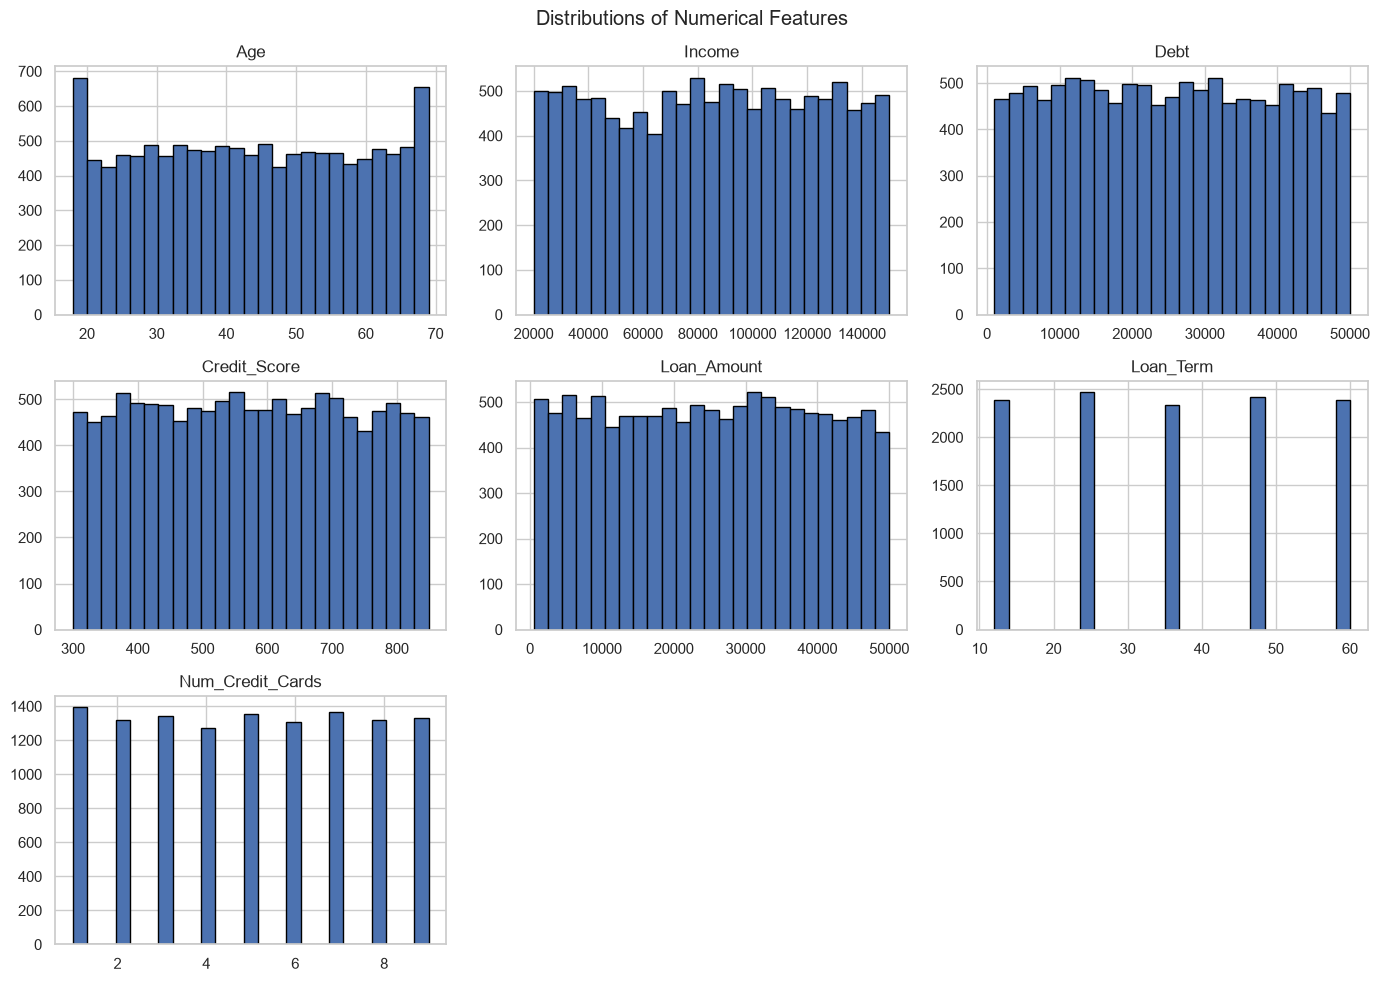

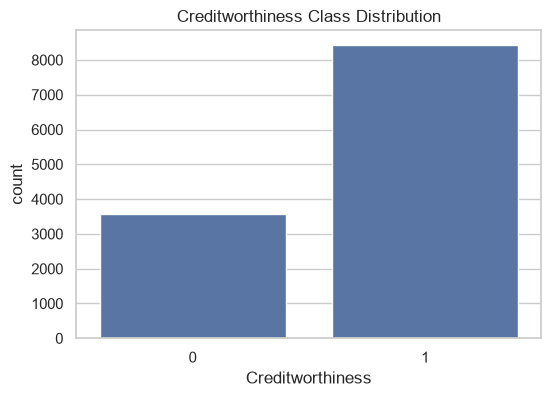

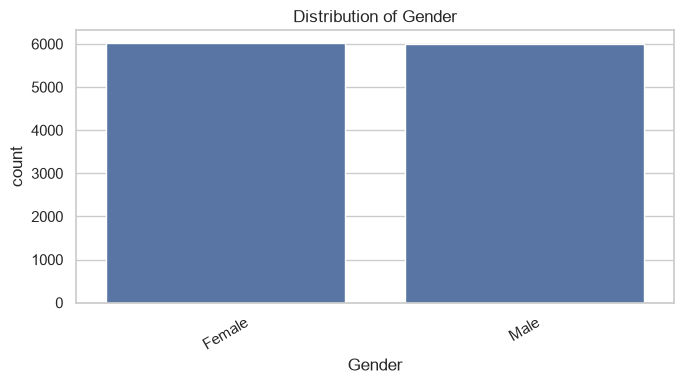

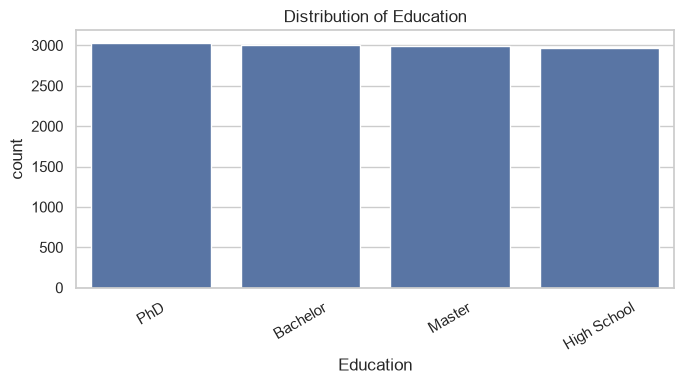

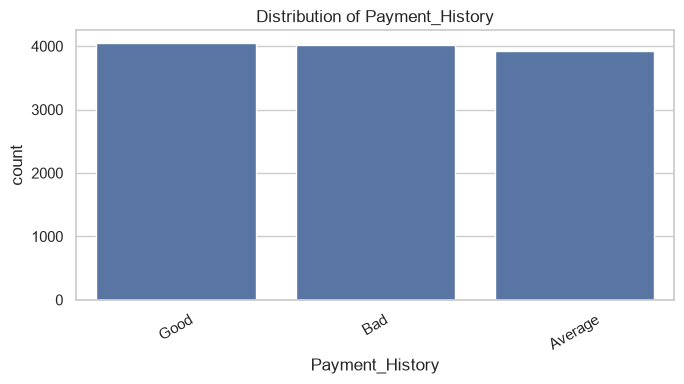

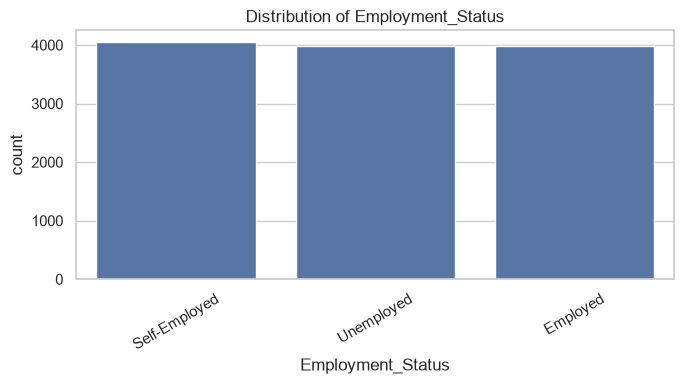

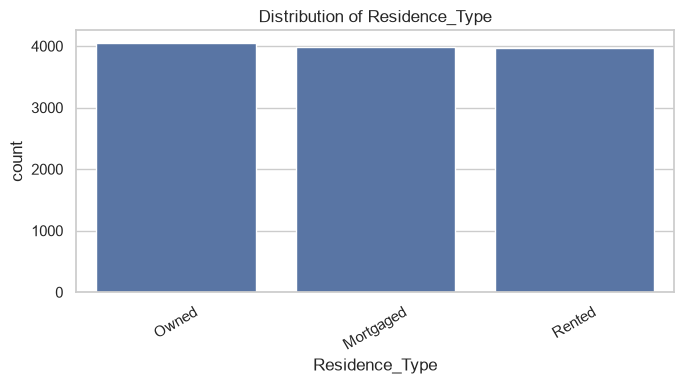

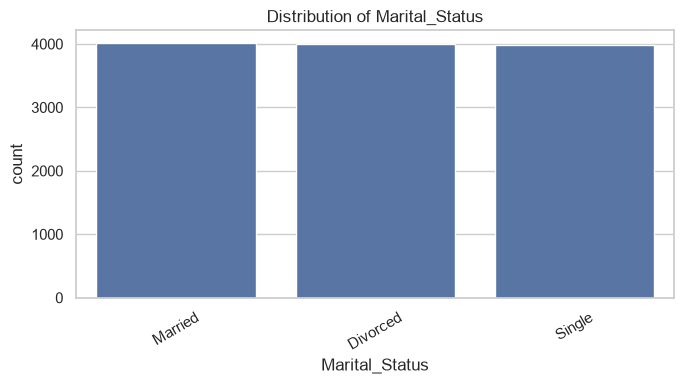

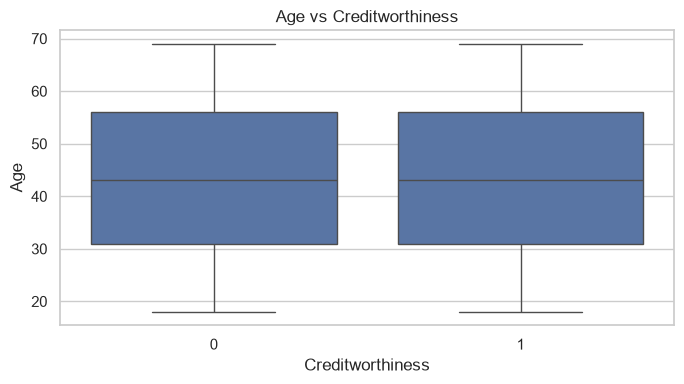

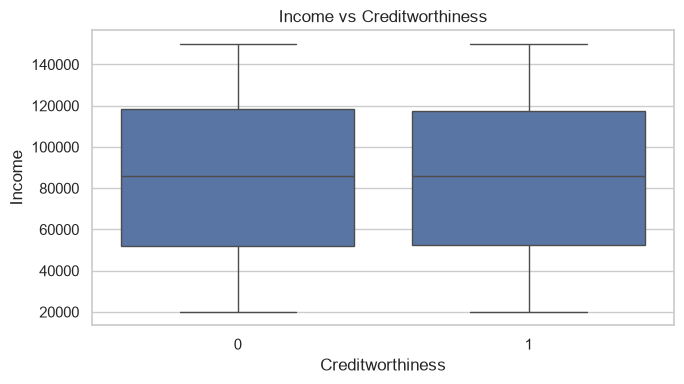

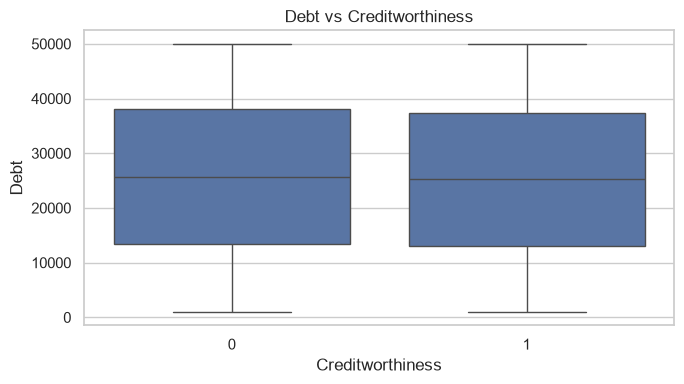

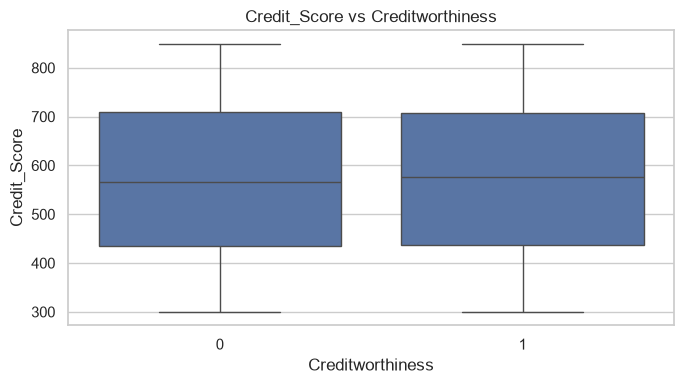

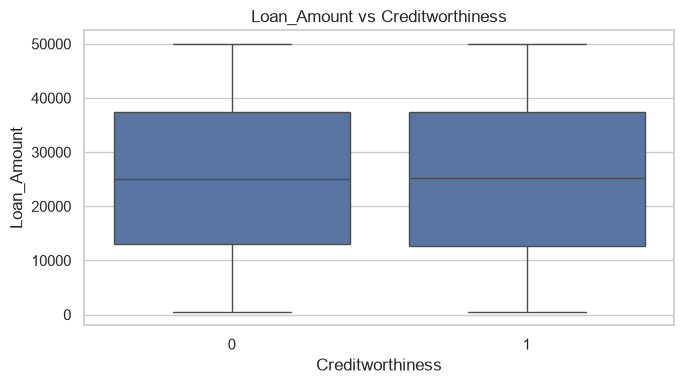

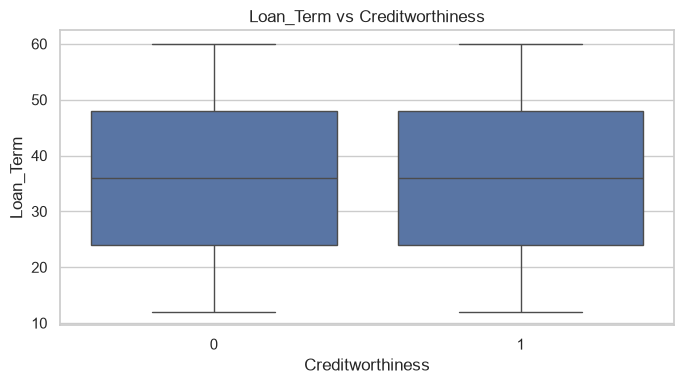

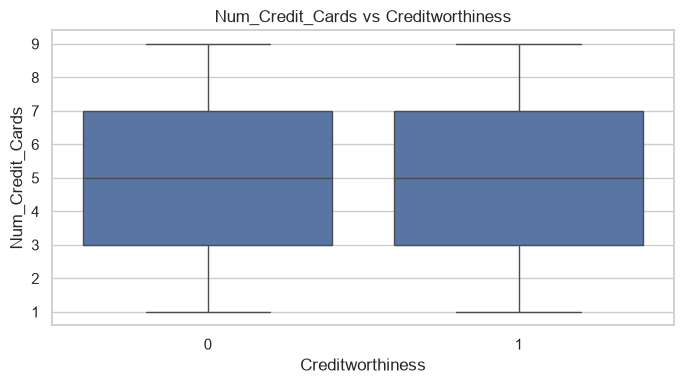

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Numerical feature distributions
numerical_columns = [
    "Age",
    "Income",
    "Debt",
    "Credit_Score",
    "Loan_Amount",
    "Loan_Term",
    "Num_Credit_Cards"
]

df[numerical_columns].hist(
    figsize=(14, 10),
    bins=25,
    edgecolor="black"
)

plt.suptitle("Distributions of Numerical Features")
plt.tight_layout()
plt.show()


# 2. Target distribution
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="Creditworthiness"
)

plt.title("Creditworthiness Class Distribution")
plt.show()


# 3. Categorical feature distributions
categorical_columns = [
    "Gender",
    "Education",
    "Payment_History",
    "Employment_Status",
    "Residence_Type",
    "Marital_Status"
]

for column in categorical_columns:
    plt.figure(figsize=(7, 4))

    sns.countplot(
        data=df,
        x=column,
        order=df[column].value_counts().index
    )

    plt.title(f"Distribution of {column}")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()


# 4. Numerical features compared with target
for column in numerical_columns:
    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df,
        x="Creditworthiness",
        y=column
    )

    plt.title(f"{column} vs Creditworthiness")
    plt.tight_layout()
    plt.show()

Correlation with Creditworthiness:
Creditworthiness    1.000000
Loan_Term           0.011225
Credit_Score        0.009058
Num_Credit_Cards    0.007342
Loan_Amount        -0.003890
Age                -0.005917
Income             -0.006074
Debt               -0.014322
Name: Creditworthiness, dtype: float64


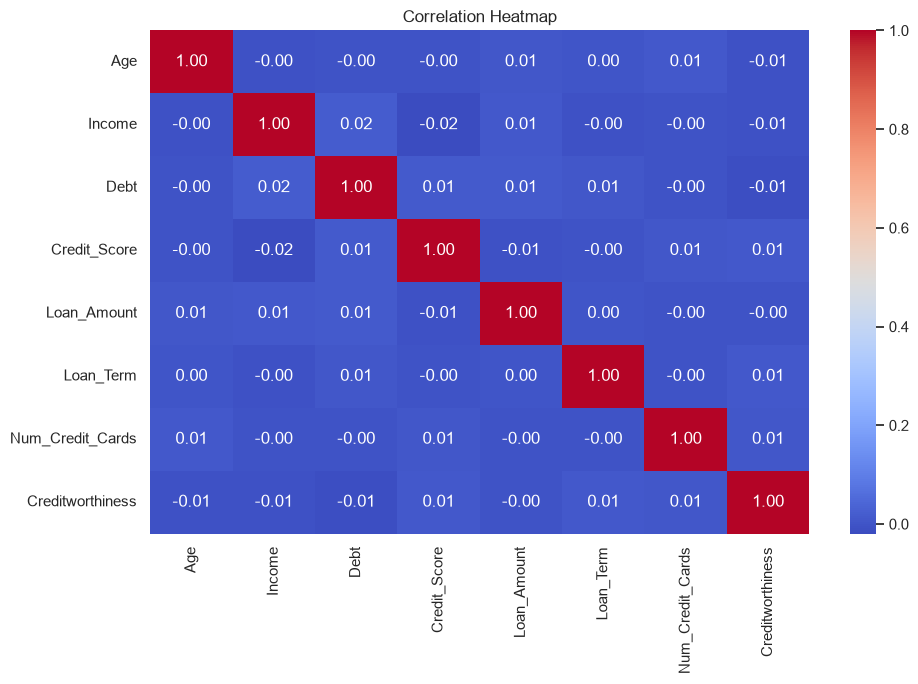


Creditworthiness rate by Gender:
        count      mean  percentage_good
Gender                                  
Female   6012  0.700432        70.043247
Male     5988  0.704743        70.474282

Creditworthiness rate by Education:
             count      mean  percentage_good
Education                                    
Bachelor      3006  0.701929        70.192947
High School   2966  0.702967        70.296696
Master        2995  0.694157        69.415693
PhD           3033  0.711177        71.117705

Creditworthiness rate by Payment_History:
                 count      mean  percentage_good
Payment_History                                  
Average           3930  0.710433        71.043257
Bad               4025  0.699130        69.913043
Good              4045  0.698393        69.839308

Creditworthiness rate by Employment_Status:
                   count      mean  percentage_good
Employment_Status                                  
Employed            3975  0.705409        70.54

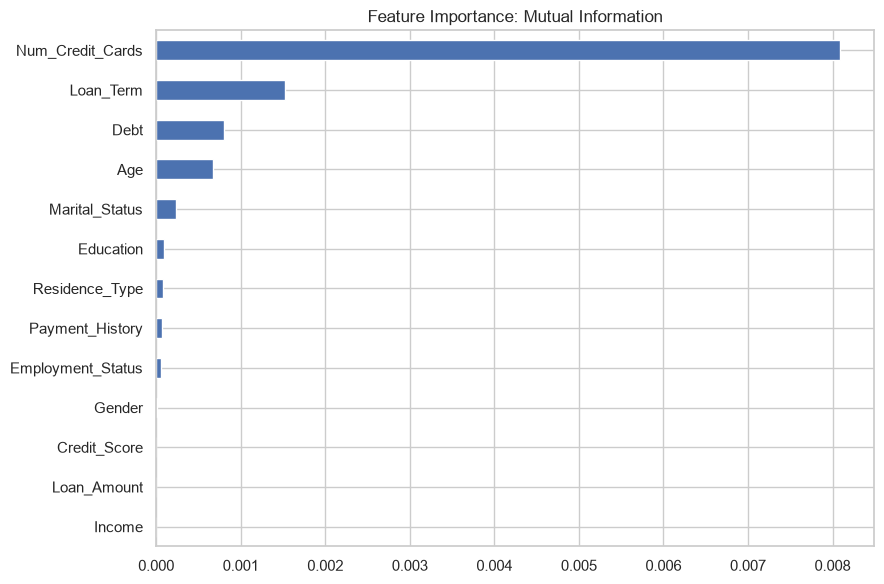

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Correlation between numerical features and target

correlation = df.corr(numeric_only=True)

print("Correlation with Creditworthiness:")
print(
    correlation["Creditworthiness"]
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


# 2. Creditworthiness rate by categorical feature

categorical_columns = [
    "Gender",
    "Education",
    "Payment_History",
    "Employment_Status",
    "Residence_Type",
    "Marital_Status"
]

for column in categorical_columns:

    print(f"\nCreditworthiness rate by {column}:")

    result = df.groupby(column)["Creditworthiness"].agg(
        ["count", "mean"]
    )

    result["percentage_good"] = result["mean"] * 100

    print(result)


# 3. Mutual information

from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import OrdinalEncoder

X = df.drop(columns=["Creditworthiness"]).copy()
y = df["Creditworthiness"]

categorical_columns = X.select_dtypes(
    include=["str", "object", "category"]
).columns.tolist()

numerical_columns = X.select_dtypes(
    include=["number"]
).columns.tolist()

# Encode categorical variables for this EDA calculation only
X_encoded = X.copy()

if categorical_columns:

    encoder = OrdinalEncoder()

    X_encoded[categorical_columns] = encoder.fit_transform(
        X_encoded[categorical_columns]
    )

mi_scores = mutual_info_classif(
    X_encoded,
    y,
    discrete_features=[
        column in categorical_columns
        for column in X_encoded.columns
    ],
    random_state=42
)

mi_results = pd.Series(
    mi_scores,
    index=X_encoded.columns
).sort_values(ascending=False)

print("\nMutual Information Scores:")
print(mi_results)

mi_results.sort_values().plot(
    kind="barh",
    figsize=(9, 6),
    title="Feature Importance: Mutual Information"
)

plt.tight_layout()
plt.show()


## 5. Data Preprocessing and Feature Preparation

Separate the numerical and categorical features.

- StandardScaler is used to scale numerical features.
- OneHotEncoder converts categorical features into numerical representations.
- ColumnTransformer combines both preprocessing operations.

The preprocessing steps are fitted only on training data to prevent data leakage.

## 6. Train-Test Split

Split the dataset into training and testing sets using an 80:20 ratio.

Stratified sampling maintains approximately the same target-class distribution in both sets.

Random state 42 ensures reproducibility.


In [5]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 1. Separate features and target

X = df.drop(columns=["Creditworthiness"])
y = df["Creditworthiness"]


# 2. Identify numerical and categorical columns

numerical_columns = [
    "Age",
    "Income",
    "Debt",
    "Credit_Score",
    "Loan_Amount",
    "Loan_Term",
    "Num_Credit_Cards"
]

categorical_columns = [
    "Gender",
    "Education",
    "Payment_History",
    "Employment_Status",
    "Residence_Type",
    "Marital_Status"
]


# 3. Split before fitting any preprocessing

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


# 4. Create preprocessing pipelines

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            StandardScaler(),
            numerical_columns
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        )
    ]
)


# 5. Fit preprocessing ONLY on training data

X_train_processed = preprocessor.fit_transform(X_train)

# Apply the already-fitted preprocessing to test data
X_test_processed = preprocessor.transform(X_test)


# 6. Inspect the results

print("Original training shape:", X_train.shape)
print("Original testing shape:", X_test.shape)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Original training shape: (9600, 13)
Original testing shape: (2400, 13)
Processed training shape: (9600, 25)
Processed testing shape: (2400, 25)

Training target distribution:
Creditworthiness
1    0.702604
0    0.297396
Name: proportion, dtype: float64

Testing target distribution:
Creditworthiness
1    0.7025
0    0.2975
Name: proportion, dtype: float64



## 7. Baseline Model

Use DummyClassifier with the most frequent strategy to establish a baseline.

This provides a reference point for evaluating whether the machine learning models learn useful patterns beyond predicting the majority class.


In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# 1. Create baseline model

baseline_model = DummyClassifier(
    strategy="most_frequent"
)

# 2. Train baseline model

baseline_model.fit(
    X_train_processed,
    y_train
)

# 3. Generate predictions

y_pred_baseline = baseline_model.predict(
    X_test_processed
)

# 4. Calculate probability scores for ROC-AUC

y_prob_baseline = baseline_model.predict_proba(
    X_test_processed
)[:, 1]

# 5. Evaluate model

print("BASELINE MODEL RESULTS")

print(
    "Accuracy:",
    accuracy_score(y_test, y_pred_baseline)
)

print(
    "Precision:",
    precision_score(
        y_test,
        y_pred_baseline,
        pos_label=0,
        zero_division=0
    )
)

print(
    "Recall:",
    recall_score(
        y_test,
        y_pred_baseline,
        pos_label=0,
        zero_division=0
    )
)

print(
    "F1-Score:",
    f1_score(
        y_test,
        y_pred_baseline,
        pos_label=0,
        zero_division=0
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y_test,
        y_prob_baseline
    )
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred_baseline,
        zero_division=0
    )
)

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        y_test,
        y_pred_baseline
    )
)

BASELINE MODEL RESULTS
Accuracy: 0.7025
Precision: 0.0
Recall: 0.0
F1-Score: 0.0
ROC-AUC: 0.5

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       714
           1       0.70      1.00      0.83      1686

    accuracy                           0.70      2400
   macro avg       0.35      0.50      0.41      2400
weighted avg       0.49      0.70      0.58      2400


Confusion Matrix:
[[   0  714]
 [   0 1686]]



## 8. Classification Model Training

Train and compare three supervised classification algorithms:

1. Logistic Regression
2. Decision Tree Classifier
3. Random Forest Classifier

All models use the same training and test split for a fair comparison.

## 9. Model Evaluation and Comparison

Evaluate model performance using:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Confusion Matrix

Class 0 (Bad creditworthiness) is treated as the positive class for precision, recall, and F1-score.

Compare the models and examine their ability to identify Bad-credit records.


In [7]:
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# 1. Define the models

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}


# 2. Store evaluation results

results = []
trained_models = {}


# 3. Train and evaluate each model

for name, model in models.items():

    print(f"\nTraining {name}...")

    # Train
    model.fit(X_train_processed, y_train)

    # Predictions
    y_pred = model.predict(X_test_processed)

    # Find probability column for class 0
    class_0_index = list(model.classes_).index(0)

    y_prob_bad = model.predict_proba(
        X_test_processed
    )[:, class_0_index]

    # Evaluate with class 0 as the positive class
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred,
        pos_label=0,
        zero_division=0
    )

    recall = recall_score(
        y_test, y_pred,
        pos_label=0,
        zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred,
        pos_label=0,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        (y_test == 0).astype(int),
        y_prob_bad
    )

    # Save results
    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision_Class_0": precision,
        "Recall_Class_0": recall,
        "F1_Class_0": f1,
        "ROC_AUC_Class_0": roc_auc
    })

    trained_models[name] = model

    # Display confusion matrix
    print("\nConfusion Matrix:")
    print(confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    ))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))


# 4. Compare all models

results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON")
print(
    results_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


Training Logistic Regression...

Confusion Matrix:
[[   0  714]
 [   0 1686]]

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       714
           1       0.70      1.00      0.83      1686

    accuracy                           0.70      2400
   macro avg       0.35      0.50      0.41      2400
weighted avg       0.49      0.70      0.58      2400


Training Decision Tree...

Confusion Matrix:
[[ 237  477]
 [ 545 1141]]

Classification Report:
              precision    recall  f1-score   support

           0       0.30      0.33      0.32       714
           1       0.71      0.68      0.69      1686

    accuracy                           0.57      2400
   macro avg       0.50      0.50      0.50      2400
weighted avg       0.59      0.57      0.58      2400


Training Random Forest...

Confusion Matrix:
[[   3  711]
 [   8 1678]]

Classification Report:
              precision    recall  f1-score   sup


## 10. Classification Threshold Analysis

Explore how changing the Logistic Regression classification threshold affects precision, recall, and F1-score for class 0.

This experiment demonstrates the trade-off between identifying more Bad-credit records and generating false-positive predictions.

The threshold results are exploratory because the test set was used for this analysis.


In [8]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Obtain probability of class 0
logistic_model = trained_models["Logistic Regression"]

class_0_index = list(
    logistic_model.classes_
).index(0)

prob_bad = logistic_model.predict_proba(
    X_test_processed
)[:, class_0_index]


# Try several thresholds for analysis
thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]

threshold_results = []

for threshold in thresholds:

    predictions = (
        prob_bad >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision_Class_0": precision_score(
            y_test,
            predictions,
            pos_label=0,
            zero_division=0
        ),
        "Recall_Class_0": recall_score(
            y_test,
            predictions,
            pos_label=0,
            zero_division=0
        ),
        "F1_Class_0": f1_score(
            y_test,
            predictions,
            pos_label=0,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.to_string(index=False))

 Threshold  Precision_Class_0  Recall_Class_0  F1_Class_0
       0.3           0.288921        0.558824    0.380907
       0.4           0.297500        1.000000    0.458574
       0.5           0.297500        1.000000    0.458574
       0.6           0.297500        1.000000    0.458574
       0.7           0.297500        1.000000    0.458574


Minimum probability: 0.24351222607115564
Maximum probability: 0.3484556110078382

Probability summary:
count    2400.000000
mean        0.296973
std         0.016789
min         0.243512
10%         0.275698
25%         0.284883
50%         0.296422
75%         0.308518
90%         0.319084
max         0.348456
dtype: float64


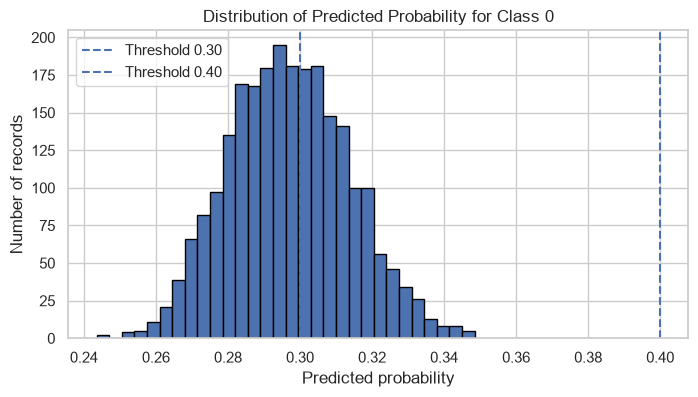

In [9]:
print("Minimum probability:", prob_bad.min())
print("Maximum probability:", prob_bad.max())

print("\nProbability summary:")
print(
    pd.Series(prob_bad).describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
    )
)

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.hist(prob_bad, bins=30, edgecolor="black")

plt.axvline(
    0.30,
    linestyle="--",
    label="Threshold 0.30"
)

plt.axvline(
    0.40,
    linestyle="--",
    label="Threshold 0.40"
)

plt.title("Distribution of Predicted Probability for Class 0")
plt.xlabel("Predicted probability")
plt.ylabel("Number of records")
plt.legend()
plt.show()

In [10]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.25, 0.28, 0.30, 0.32, 0.35, 0.40]

for threshold in thresholds:

    predictions = np.where(prob_bad >= threshold, 0, 1)

    precision = precision_score(
        y_test, predictions, pos_label=0, zero_division=0
    )

    recall = recall_score(
        y_test, predictions, pos_label=0, zero_division=0
    )

    f1 = f1_score(
        y_test, predictions, pos_label=0, zero_division=0
    )

    print(f"\nThreshold: {threshold}")
    print(f"Class 0 Precision: {precision:.4f}")
    print(f"Class 0 Recall:    {recall:.4f}")
    print(f"Class 0 F1-score:  {f1:.4f}")


Threshold: 0.25
Class 0 Precision: 0.2977
Class 0 Recall:    1.0000
Class 0 F1-score:  0.4589

Threshold: 0.28
Class 0 Precision: 0.3018
Class 0 Recall:    0.8501
Class 0 F1-score:  0.4455

Threshold: 0.3
Class 0 Precision: 0.3091
Class 0 Recall:    0.4412
Class 0 F1-score:  0.3635

Threshold: 0.32
Class 0 Precision: 0.3019
Class 0 Recall:    0.0896
Class 0 F1-score:  0.1382

Threshold: 0.35
Class 0 Precision: 0.0000
Class 0 Recall:    0.0000
Class 0 F1-score:  0.0000

Threshold: 0.4
Class 0 Precision: 0.0000
Class 0 Recall:    0.0000
Class 0 F1-score:  0.0000



## 11. Conclusion

Summarize the model comparison, key findings, and limitations.

The tested models showed weak predictive discrimination on this synthetic dataset.

Discuss possible improvements, including more informative financial features, better-documented datasets, and validation-based model selection and threshold tuning.
